# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

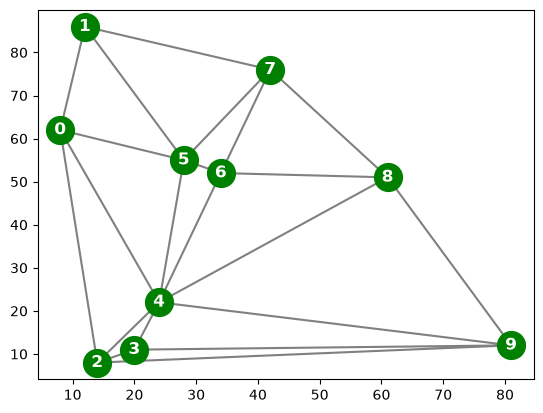

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [42]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [43]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [44]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [45]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## To do test the complete and consistent function

In [46]:

# ===== TEST COMPLETE =====

variables = list(csp["variables"])

complete_tests = [
    ({}, False), 
    ({v: "red" for v in variables[:-1]}, False),
    ({v: "red" for v in variables}, True)
]

print("TEST COMPLETE")
for i, (assignment, expected) in enumerate(complete_tests, 1):
    result = complete(assignment, csp)
    print(f"Test {i}: {result} | Expected: {expected}")
    assert result == expected


# ===== TEST CONSISTENT =====

# Chọn hai đỉnh có cạnh nối trong đồ thị
u, v = next(iter(csp["constraints"]))

consistent_tests = [
    ({}, True),
    ({u: "red", v: "red"}, False),
    ({u: "red", v: "blue"}, True)
]

print("\nTEST CONSISTENT")
for i, (assignment, expected) in enumerate(consistent_tests, 1):
    result = consistent(assignment, csp)
    print(f"Test {i}: {result} | Expected: {expected}")
    assert result == expected


TEST COMPLETE
Test 1: False | Expected: False
Test 2: False | Expected: False
Test 3: True | Expected: True

TEST CONSISTENT
Test 1: True | Expected: True
Test 2: False | Expected: False
Test 3: True | Expected: True


Through our tests, the complete() function correctly determined if the graph was fully colored, and the consistent() function checked the coloring constraints between adjacent nodes. All six test cases produced the expected outcomes.

## Implement Simple Backtracking Search

In [47]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)

def select_unassigned_var(assignment, csp):
    unassigned = [
        v for v in csp['variables']
        if v not in assignment
    ]

    if not unassigned:
        return None

    def count_remaining_values(v):
        used_colors = set()

        for u, w in csp['constraints']:
            if u == v and w in assignment:
                used_colors.add(assignment[w])
            elif w == v and u in assignment:
                used_colors.add(assignment[u])

        return sum(
            color not in used_colors
            for color in csp['domains'][v]
        )

    return min(unassigned, key=count_remaining_values)


print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 5


In [48]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

# LCV: Least Constraining Value
def order_domain(assignment, var, csp):
    # Lấy các đỉnh kề chưa được tô màu
    neighbors = set()

    for u, v in csp['constraints']:
        if u == var and v not in assignment:
            neighbors.add(v)
        elif v == var and u not in assignment:
            neighbors.add(u)

    # Đếm số lựa chọn hợp lệ bị loại nếu chọn màu này
    def eliminated_options(color):
        count = 0

        for neighbor in neighbors:
            if color not in csp['domains'][neighbor]:
                continue

            still_allowed = True

            for a, b in csp['constraints']:
                if a == neighbor and b in assignment:
                    if assignment[b] == color:
                        still_allowed = False
                        break
                elif b == neighbor and a in assignment:
                    if assignment[a] == color:
                        still_allowed = False
                        break

            if still_allowed:
                count += 1

        return count

    # Màu loại ít lựa chọn nhất được thử trước
    return sorted(
        csp['domains'][var],
        key=eliminated_options
    )

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in order_domain(assignment, var, csp):
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

In [49]:

# Test LCV với một đồ thị nhỏ có đáp án xác định
test_csp = {
    'variables': ['A', 'B', 'C'],
    'domains': {
        'A': ['red', 'blue', 'green'],
        'B': ['red', 'blue'],
        'C': ['red']
    },
    'constraints': [('A', 'B'), ('A', 'C')]
}

result_lcv = order_domain({}, 'A', test_csp)

print("LCV order:", result_lcv)

assert result_lcv == ['green', 'blue', 'red']
print("LCV test passed!")


LCV order: ['green', 'blue', 'red']
LCV test passed!


## Run Backtracking Search on the Random Problem

In [50]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: total: 0 ns
Wall time: 462 μs


{'0': 'red',
 '1': 'blue',
 '5': 'green',
 '4': 'blue',
 '2': 'green',
 '3': 'red',
 '9': 'orange',
 '6': 'orange',
 '7': 'red',
 '8': 'green'}

Plot the resulting coloring

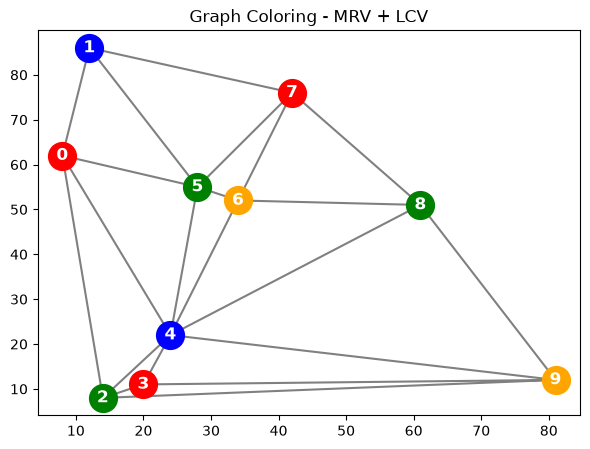

In [58]:

plt.figure(figsize=(7, 5))

plt.triplot(points[:, 0], points[:, 1],
            tri.simplices, color="gray")

for i in range(len(points)):
    color = res[str(i)]

    plt.plot(
        points[i, 0], points[i, 1],
        'o', color=color, markersize=20
    )

    plt.annotate(
        str(i), points[i, :],
        color='white',
        fontsize='large',
        weight='bold',
        horizontalalignment='center',
        verticalalignment='center'
    )

plt.title("Graph Coloring - MRV + LCV")
plt.show()


In [52]:
print("Complete:", complete(res, csp))
print("Consistent:", consistent(res, csp))

assert complete(res, csp)
assert consistent(res, csp)

Complete: True
Consistent: True


## Experiment — Compare Backtracking, MRV and MRV + LCV

This cell runs each variant on the same graph with 3 and 4 colors, then compares multiple Delaunay graphs with fixed seeds. It measures search nodes (COUNT), attempted color assignments, run time, and status (solved/unsat/limit). Run all earlier cells first.

=== SO SANH TREN CUNG DO THI GOC ===


,so_dinh,so_mau,thuat_toan,status,nodes,attempts,time_ms
0,10,3,Backtracking goc,unsat,70,210,0.4390
1,10,3,BT + MRV,unsat,34,102,0.5337
2,10,3,BT + MRV + LCV,unsat,34,102,0.8645
3,10,4,Backtracking goc,solved,11,23,0.0718
4,10,4,BT + MRV,solved,11,24,0.1687
5,10,4,BT + MRV + LCV,solved,11,28,0.2728


solved = tim duoc nghiem; unsat = da duyet het va khong co nghiem; limit = cham gioi han node, chua ket luan.

=== TONG HOP NHIEU KICH THUOC / 3-4 MAU ===


,n,so_mau,thuat_toan,so_luot,thanh_cong_pct,vo_nghiem,cham_gioi_han,canh_trung_binh,COUNT_TB,luot_thu_gan_TB,thoi_gian_ms_TB
0,10,3,BT + MRV,3,0.0,3,0,20.67,40.00,120.00,0.60
1,10,3,BT + MRV + LCV,3,0.0,3,0,20.67,40.00,120.00,1.12
2,10,3,Backtracking goc,3,0.0,3,0,20.67,58.00,174.00,0.44
3,10,4,BT + MRV,3,100.0,0,0,20.67,11.00,21.67,0.15
4,10,4,BT + MRV + LCV,3,100.0,0,0,20.67,11.00,24.33,0.25
5,10,4,Backtracking goc,3,100.0,0,0,20.67,11.00,21.67,0.08
6,20,3,BT + MRV,3,0.0,3,0,48.33,46.00,138.00,2.35
7,20,3,BT + MRV + LCV,3,0.0,3,0,48.33,46.00,138.00,3.28
8,20,3,Backtracking goc,3,0.0,3,0,48.33,110.00,330.00,1.54
9,20,4,BT + MRV,3,100.0,0,0,48.33,21.00,45.33,0.73


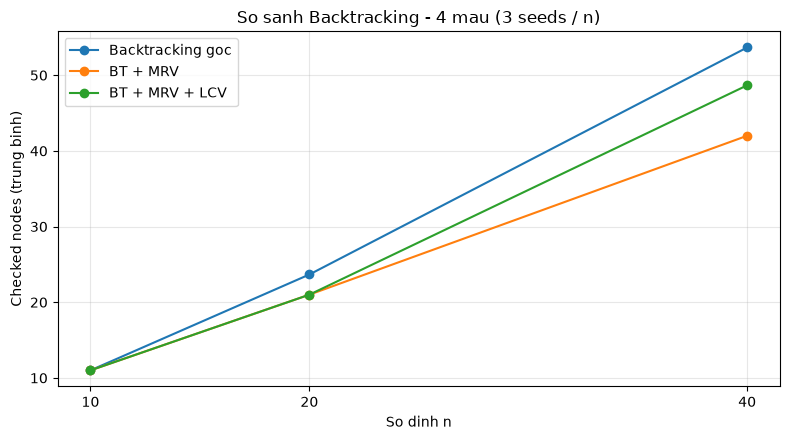

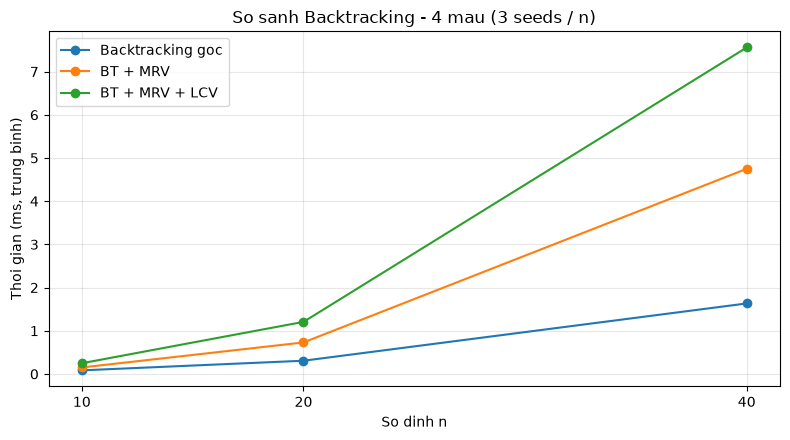

In [55]:
# LAB04 - So sanh Backtracking goc, MRV, MRV + LCV
# Dat cell nay sau khi da chay cac cell dinh nghia csp, complete,
# consistent, select_unassigned_var (MRV), order_domain (LCV).
import time
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial import Delaunay

ALGORITHMS = [
    ('Backtracking goc', False, False),
    ('BT + MRV', True, False),
    ('BT + MRV + LCV', True, True),
]
MAX_NODES = 20000


def solve_for_comparison(problem, mrv=False, lcv=False, max_nodes=MAX_NODES):
    nodes = 0       # So lan goi de quy, tuong duong COUNT trong notebook
    attempts = 0    # So lan thu gan mau, ke ca mau vi pham

    class NodeLimit(Exception):
        pass

    def search(assignment):
        nonlocal nodes, attempts
        nodes += 1
        if nodes > max_nodes:
            raise NodeLimit()
        if complete(assignment, problem):
            return assignment.copy()

        if mrv:
            var = select_unassigned_var(assignment, problem)
        else:
            var = next(v for v in problem['variables'] if v not in assignment)

        colors = (order_domain(assignment, var, problem)
                  if lcv else problem['domains'][var])
        for color in colors:
            attempts += 1
            assignment[var] = color
            if consistent(assignment, problem):
                result = search(assignment)
                if result is not None:
                    return result
            del assignment[var]
        return None

    t0 = time.perf_counter()
    try:
        solution = search({})
        status = 'solved' if solution is not None else 'unsat'
    except NodeLimit:
        solution = None
        status = 'limit'
    elapsed_ms = (time.perf_counter() - t0) * 1000

    if solution is not None:
        assert complete(solution, problem) and consistent(solution, problem)

    return {'status': status, 'nodes': nodes,
            'attempts': attempts, 'time_ms': elapsed_ms}


def with_k_colors(problem, k):
    # Tao ban sao CSP: giu nguyen do thi, chi thay so mau
    base_colors = list(problem['domains'][problem['variables'][0]])
    assert len(base_colors) >= k, f'CSP phai co it nhat {k} mau'
    return {
        'variables': list(problem['variables']),
        'domains': {v: base_colors[:k].copy() for v in problem['variables']},
        'constraints': list(problem['constraints']),
    }


# A. SO SANH 3 THUAT TOAN TREN DUNG DO THI GOC n=10
rows = []
for k in (3, 4):
    problem = with_k_colors(csp, k)
    for name, mrv, lcv in ALGORITHMS:
        r = solve_for_comparison(problem, mrv, lcv)
        rows.append({'so_dinh': len(problem['variables']), 'so_mau': k,
                     'thuat_toan': name, **r})

comparison = pd.DataFrame(rows)
print('=== SO SANH TREN CUNG DO THI GOC ===')
display(comparison)
print('solved = tim duoc nghiem; unsat = da duyet het va khong co nghiem; '
      'limit = cham gioi han node, chua ket luan.')


# B. THU NGHIEM NHIEU KICH THUOC (doi thiet lap neu can)
RUN_MULTI_SIZE = True
SIZES = [10, 20, 40]
SEEDS = [1, 2, 3]  # 3 do thi ngau nhien / moi kich thuoc


def make_random_csp(n, seed, colors):
    rng = np.random.default_rng(seed)
    points = rng.random((n, 2)) * 100
    points = points[np.argsort(points[:, 0])]
    tri = Delaunay(points)
    edges = set()
    for a, b, c in tri.simplices:
        for u, v in [(a, b), (b, c), (a, c)]:
            edges.add(tuple(sorted((int(u), int(v)))))
    variables = [str(i) for i in range(n)]
    return {
        'variables': variables,
        'domains': {v: list(colors) for v in variables},
        'constraints': [(str(u), str(v)) for u, v in sorted(edges)],
    }

if RUN_MULTI_SIZE:
    extended_rows = []
    palette = list(csp['domains'][csp['variables'][0]])
    for n in SIZES:
        for seed in SEEDS:
            for k in (3, 4):
                problem = make_random_csp(n, seed, palette[:k])
                for name, mrv, lcv in ALGORITHMS:
                    r = solve_for_comparison(problem, mrv, lcv)
                    extended_rows.append({'n': n, 'seed': seed, 'so_mau': k,
                                          'so_canh': len(problem['constraints']),
                                          'thuat_toan': name, **r})

    extended = pd.DataFrame(extended_rows)
    summary = (extended.groupby(['n', 'so_mau', 'thuat_toan'], as_index=False)
               .agg(so_luot=('status', 'size'),
                    thanh_cong_pct=('status', lambda s: round((s == 'solved').mean()*100, 1)),
                    vo_nghiem=('status', lambda s: (s == 'unsat').sum()),
                    cham_gioi_han=('status', lambda s: (s == 'limit').sum()),
                    canh_trung_binh=('so_canh', 'mean'),
                    COUNT_TB=('nodes', 'mean'),
                    luot_thu_gan_TB=('attempts', 'mean'),
                    thoi_gian_ms_TB=('time_ms', 'mean')))
    print('\n=== TONG HOP NHIEU KICH THUOC / 3-4 MAU ===')
    display(summary.round(2))

    # Hai bieu do danh cho truong hop 4 mau (bao gom cac luot 'limit' neu co).
    # Neu co 'limit', COUNT va thoi gian la chi phi tai diem dung, khong phai giai xong.
    import matplotlib.pyplot as plt
    four_colors = summary[summary['so_mau'] == 4]
    for metric, ylabel, filename in [
        ('COUNT_TB', 'Checked nodes (trung binh)', 'BT_MRV_LCV_nodes.png'),
        ('thoi_gian_ms_TB', 'Thoi gian (ms, trung binh)', 'BT_MRV_LCV_time.png'),
    ]:
        plt.figure(figsize=(8, 4.5))
        for name, _, _ in ALGORITHMS:
            sub = four_colors[four_colors['thuat_toan'] == name].sort_values('n')
            plt.plot(sub['n'], sub[metric], marker='o', label=name)
        plt.title(f'So sanh Backtracking - 4 mau ({len(SEEDS)} seeds / n)')
        plt.xlabel('So dinh n')
        plt.ylabel(ylabel)
        plt.xticks(SIZES)
        plt.grid(alpha=.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


## Nhận xét kết quả thực nghiệm

### 1. Hiệu quả của MRV

Kết quả cho thấy MRV giúp giảm số nút tìm kiếm (COUNT) so với Backtracking cơ bản trong nhiều trường hợp.

- Với đồ thị 10 đỉnh và 3 màu, COUNT giảm từ 70 xuống 34, tương đương khoảng **51,4%**.
- Với đồ thị 40 đỉnh và 3 màu, COUNT trung bình giảm từ 114 xuống 48, tương đương khoảng **57,9%**.
- Với đồ thị 40 đỉnh và 4 màu, COUNT trung bình giảm từ 53,67 xuống 42.

Điều này cho thấy việc ưu tiên biến có ít giá trị hợp lệ còn lại giúp phát hiện sớm các nhánh không thể dẫn đến nghiệm, từ đó giảm số lần tìm kiếm.

### 2. Hiệu quả của LCV

Khi kết hợp MRV với LCV, số nút tìm kiếm không phải lúc nào cũng giảm thêm.

Ở trường hợp 3 màu, MRV và MRV + LCV cho cùng COUNT trong các thí nghiệm. Với 4 màu và 40 đỉnh, COUNT trung bình của MRV + LCV là 48,67, cao hơn MRV đơn lẻ (42).

Nguyên nhân là LCV chỉ thay đổi thứ tự thử màu nhằm giữ lại nhiều lựa chọn cho các đỉnh lân cận, không đảm bảo luôn tìm được nghiệm nhanh hơn. Hiệu quả của LCV phụ thuộc vào cấu trúc đồ thị và trạng thái tìm kiếm.

### 3. So sánh thời gian thực thi

Mặc dù MRV và LCV có thể giảm COUNT, thời gian thực thi chưa chắc được cải thiện.

Ví dụ, với đồ thị 40 đỉnh và 3 màu:

- Backtracking cơ bản: 1,65 ms.
- Backtracking + MRV: 8,84 ms.
- Backtracking + MRV + LCV: 9,69 ms.

Nguyên nhân là MRV cần tính số giá trị hợp lệ còn lại, trong khi LCV phải đánh giá mức độ ảnh hưởng của từng màu lên các đỉnh lân cận. Các thao tác này tạo thêm chi phí tính toán.

### 4. Ảnh hưởng của số màu

Trong các đồ thị được thử nghiệm:

- **3 màu:** Cả ba thuật toán đều không tìm được nghiệm. Các lần chạy kết thúc sau khi duyệt hết các khả năng hợp lệ.
- **4 màu:** Cả ba thuật toán đều tìm được nghiệm hợp lệ, đạt tỷ lệ thành công 100%.

Điều này cho thấy việc tăng số màu giúp bài toán dễ tìm được nghiệm hơn trên các đồ thị đã khảo sát.

### 5. Kết luận

Qua thực nghiệm, MRV cho thấy khả năng giảm số nút trong cây tìm kiếm Backtracking. Tuy nhiên, việc kết hợp thêm LCV không đảm bảo cải thiện hiệu quả trong mọi trường hợp.

Số nút tìm kiếm ít hơn cũng không đồng nghĩa với thời gian chạy ngắn hơn, do chi phí tính toán

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.